# LEGEND NREFT outlook — $\mathcal O_8$ and $\mathcal O_{11}$

**One notebook for setup, execution, and plotting**, using the existing WIMP-LEGEND implementation. No dependency on `poster_figures.py` or the SI campaign helpers.

The test uses **three masses (3, 5, 15 GeV)** and two single-operator models, $\mathcal O_8=\mathbf S_\chi\cdot\mathbf v^\perp$ and $\mathcal O_{11}=i\mathbf S_\chi\cdot\mathbf q/m_N$.

- **`WRITE_CONFIG`** controls whether to build/save a dedicated NREFT configuration.
- **`RUN_ANALYSIS`** controls whether any rate or detector calculation is executed.
- **`PLOT_NORMALIZED`** and **`PLOT_ABSOLUTE`** control plotting. With the first two flags `False`, the notebook loads the **previously saved, checksum-validated** run without recalculation.

All run outputs and figures live under `analyses/legend_poster/campaigns/nreft_test/`. The detector-folding backend is **vectorized**. The SI-only rate accelerator is **not applicable** to $\mathcal O_8/\mathcal O_{11}$, so the original generic NREFT velocity integrator remains in use.

**Scientific note:** These are provisional elastic WIMP–Ge forecasts. Normalized curves compare spectral **shapes**, not coupling strengths or sensitivity. The enriched composition and detector/background assumptions are the same hypothetical benchmark as the poster workbench.

## 1 · Flags, paths, and plotting choices

In [ ]:
# --------------------- Independent switches ---------------------
WRITE_CONFIG = False        # True: write/replace nreft_test/config.json
RUN_ANALYSIS = False        # True: calculate the 3 masses × {O8,O11}
PLOT_NORMALIZED = True      # True: make unit-area spectra
PLOT_ABSOLUTE = True        # True: make raw event-rate spectra

# --------------------- Physical/run choices ---------------------
MASSES_GEV = [3.0, 5.0, 15.0, 30, 50, 100]
OPERATORS = [1, 3, 8, 11]
SCENARIO = 'legend_poster'  # provisional enriched Ge detector and backgrounds
EXPOSURE_TONNE_YEAR = 0.1  # only used for limit records; spectra are per kg/day

# --------------------- Plot styling ---------------------
E_MIN_KEVEE = 0.10
E_MAX_KEVEE = 2.0
FIGURE_SIZE = (15.0, 4.8)
FIGURE_DPI = 220
FONT_SIZE = 13
SAVE_FIGURES = True
ABSOLUTE_LOG_Y = True

O_COLORS = {1: "#603eaa", 3: "#ffbf0e", 8: '#3e75aa', 11: '#bb4051'}

## 2 · Locate the WIMP-LEGEND checkout

In [9]:
from pathlib import Path
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd().resolve()
root_candidates = (here, *here.parents)
ROOT = next((p for p in root_candidates
             if (p/'pyproject.toml').is_file()
             and (p/'analyses/legend_poster/config.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook in the WIMP-LEGEND repository, e.g. notebooks/nreft_outlook.ipynb')

for folder in (ROOT, ROOT/'src'):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

BASE_CONFIG = ROOT/'analyses/legend_poster/config.json'
CAMPAIGN_DIR = ROOT/'analyses/legend_poster/campaigns/nreft_test'
CONFIG_PATH = CAMPAIGN_DIR/'config.json'
RUNS_DIR = CAMPAIGN_DIR/'runs'
RUN_POINTER = CAMPAIGN_DIR/'last_run.json'
FIGURE_DIR = CAMPAIGN_DIR/'figures'

# Share only the existing content-addressed, provenance-checked numerical cache.
# The NREFT output and figure directories remain entirely separate.
CACHE_DIR = ROOT/'analyses/legend_poster/cache'

print('Git checkout:', ROOT)
print('NREFT campaign:', CAMPAIGN_DIR)
print('Saved configuration:', CONFIG_PATH)
print('Flags:', dict(write=WRITE_CONFIG, run=RUN_ANALYSIS,
                    normalized=PLOT_NORMALIZED, absolute=PLOT_ABSOLUTE))

Git checkout: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code
NREFT campaign: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\nreft_test
Saved configuration: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\nreft_test\config.json
Flags: {'write': True, 'run': True, 'normalized': True, 'absolute': True}


## 3 · Write configuration (optional)

In [10]:
from copy import deepcopy
from analyses.legend_poster import load_config, save_config, validate_config

if WRITE_CONFIG:
    working = deepcopy(load_config(BASE_CONFIG))
    working['signal']['masses_GeV'] = list(MASSES_GEV)
    working['signal']['operators'] = list(OPERATORS)

    # Generic NREFT particle response + velocity integration for both operators.
    working['signal']['si_rate_engine'] = 'generic'
    # Independently accelerated detector folding (available for O8/O11 too).
    working['numerical']['folding_backend'] = 'vectorized'

    working['analysis']['scenarios'] = [SCENARIO]
    working['analysis']['exposures_kg_day'] = [
        float(EXPOSURE_TONNE_YEAR * 1000 * working['analysis']['days_per_year'])
    ]
    working['analysis']['methods'] = ['poisson_cls_counting']
    working['background']['historical']['enabled'] = False

    # Keep the accepted 'standard' integration tolerances unchanged.
    # Avoid accidental overrides inherited from a customized master profile.
    working['execution']['default_profile'] = 'standard'
    working['execution']['profiles']['standard'] = {}

    working = validate_config(working)
    path = save_config(working, CONFIG_PATH)
    print('Saved:', path)
else:
    print('WRITE_CONFIG=False: no configuration was modified.')

if CONFIG_PATH.exists():
    saved_config = load_config(CONFIG_PATH)
    print('Existing config: masses =',saved_config['signal']['masses_GeV'],
          ', operators =',saved_config['signal']['operators'],
          ', folding =',saved_config['numerical'].get('folding_backend','reference'))
else:
    saved_config = None
    print('No saved NREFT config yet. For a first run, enable WRITE_CONFIG.')

Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\nreft_test\config.json
Existing config: masses = [3.0, 5.0, 15.0, 30, 50, 100] , operators = [1, 3, 8, 11] , folding = vectorized


## 4 · Execute or reuse a calculation (optional)

In [11]:
from analyses.legend_poster import run_analysis, load_run

run = None
if RUN_ANALYSIS:
    if saved_config is None:
        raise FileNotFoundError('NREFT config missing: set WRITE_CONFIG=True and rerun.')
    from analyses.legend_poster import resolve_profile
    resolved = resolve_profile(saved_config, 'standard')
    if sorted(resolved['signal']['operators']) != [1, 3, 8, 11]:
        raise ValueError('NREFT config does not select exactly O1, O3, O8 and O11.')
    if resolved['numerical'].get('folding_backend') != 'vectorized':
        raise ValueError('Vectorized detector folding is not enabled in the saved config.')
    if resolved['analysis']['scenarios'] != [SCENARIO]:
        raise ValueError('Unexpected scenario in saved NREFT config.')

    start = time.perf_counter()
    run = run_analysis(saved_config, profile='standard',
                       cache_dir=CACHE_DIR, output_dir=RUNS_DIR)
    print(f'Full run finished in {time.perf_counter()-start:.1f} seconds.')
    print('Validated convergence checks:',len(run['convergence']))
    if not all(c['passed'] for c in run['convergence']):
        raise RuntimeError('The source run contains failed convergence checks.')

    # Atomic run pointer; no modifications to master poster campaign.
    CAMPAIGN_DIR.mkdir(parents=True,exist_ok=True)
    pointer = dict(run_id=run['manifest']['run_id'], run_directory=run['path'].name)
    tmp = RUN_POINTER.with_suffix('.json.tmp')
    tmp.write_text(json.dumps(pointer,indent=2)+'\n',encoding='utf-8')
    tmp.replace(RUN_POINTER)
    print('Saved run pointer:',RUN_POINTER)
else:
    print('RUN_ANALYSIS=False: no physics calculation or folding was performed.')

Full run finished in 8.4 seconds.
Validated convergence checks: 57
Saved run pointer: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\nreft_test\last_run.json


## 5 · Load saved results for plotting (no physics computation)

In [12]:
if PLOT_NORMALIZED or PLOT_ABSOLUTE:
    if run is None:
        if not RUN_POINTER.exists():
            raise FileNotFoundError(
                'No saved run pointer at '+str(RUN_POINTER)+'.\n'
                'Run once with WRITE_CONFIG=True and RUN_ANALYSIS=True, '
                'or set RUN_POINTER to an existing nreft_test/last_run.json.'
            )
        pointer = json.loads(RUN_POINTER.read_text(encoding='utf-8'))
        run_name = pointer['run_directory']
        if Path(run_name).name != run_name:
            raise ValueError('Unsafe run directory in pointer')
        run = load_run(RUNS_DIR / run_name)  # verifies all saved output checksums
        if run['manifest']['run_id'] != pointer['run_id']:
            raise ValueError('Saved run pointer/manifest ID mismatch')

    cfg = run['manifest']['resolved_configuration']
    available_masses = [float(v) for v in cfg['signal']['masses_GeV']]
    available_ops = list(cfg['signal']['operators'])
    actual_scenario = cfg['analysis']['scenarios']
    if len(actual_scenario)!=1:
        raise ValueError('Expected one scenario in NREFT spectrum run')
    actual_scenario = actual_scenario[0]
    if not {8,11}.issubset(set(available_ops)):
        raise ValueError('Stored run does not include both O8 and O11')

    # Plot the masses actually present in the loaded run. Changing the setup
    # flags does not silently relabel an older stored result.
    plot_masses = [m for m in MASSES_GEV if any(abs(m-v)<1e-12 for v in available_masses)]
    if len(plot_masses)!=len(MASSES_GEV):
        raise ValueError(f'Saved run mass grid {available_masses} does not contain requested {MASSES_GEV}')

    bins = np.asarray(run['signals']['observed_edges_keV'], dtype=float)
    if not np.all(np.diff(bins)>0):
        raise ValueError('Invalid observed-energy bin edges')
    observed_threshold = cfg['detector']['presets'][cfg['detector']['default']]['threshold_keV_obs']
    c_ref = cfg['signal']['coefficient_ref_GeV_minus2']
    ratio = cfg['signal']['fn_over_fp']

    # Strict complete-bin window, without interpolation or invented spectral points.
    lo = max(float(E_MIN_KEVEE), observed_threshold)
    hi = float(E_MAX_KEVEE)
    first = int(np.searchsorted(bins,lo-1e-11,side='left'))
    last = int(np.searchsorted(bins,hi+1e-11,side='right')-1)
    if not (0 <= first < last < len(bins)):
        raise ValueError('Requested energy interval is outside saved observed bins')
    view_edges = bins[first:last+1]
    widths = np.diff(view_edges)

    spectra = {}
    for mass in plot_masses:
        for op in (1,3,8,11):
            key = f'{actual_scenario}__O{op}__m{mass:g}'
            if key not in run['signals']:
                raise KeyError(f'Missing saved spectrum: {key}')
            values = np.asarray(run['signals'][key], dtype=float)
            if values.shape != (len(bins)-1,) or np.any(~np.isfinite(values)) or np.any(values<0):
                raise ValueError(f'Invalid saved spectrum {key}')
            spectra[(mass,op)] = values[first:last]

    print('Loaded checksum-verified source run:',run['path'])
    print('Actual masses/operators:',available_masses,available_ops)
    print('Observed-energy plotting window:',view_edges[0], 'to',view_edges[-1],'keVee')
    print('Reference couplings: c_p = %.3g GeV^-2; c_n / c_p = %g' % (c_ref,ratio))
    print('All spectra are per kg-day at the frozen reference Wilson coefficients.')
else:
    print('Both plotting flags are False: saved numerical results were not loaded.')

Loaded checksum-verified source run: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\nreft_test\runs\8b589378cfec8629cf78
Actual masses/operators: [3.0, 5.0, 15.0, 30.0, 50.0, 100.0] [1, 3, 8, 11]
Observed-energy plotting window: 0.1 to 2.0 keVee
Reference couplings: c_p = 1e-05 GeV^-2; c_n / c_p = 1
All spectra are per kg-day at the frozen reference Wilson coefficients.


## 6 · Normalized shapes — $\mathcal O_8$ versus $\mathcal O_{11}$

Each curve is divided by its own **total counts in the displayed $E_{\rm obs}$ window**. This compares only shape, not overall rate or Wilson-coefficient limits. No smoothed interpolation is introduced: these are the saved detector-folded observed-bin densities.

Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\nreft_test\figures\nreft_normalized_O8_O11.pdf


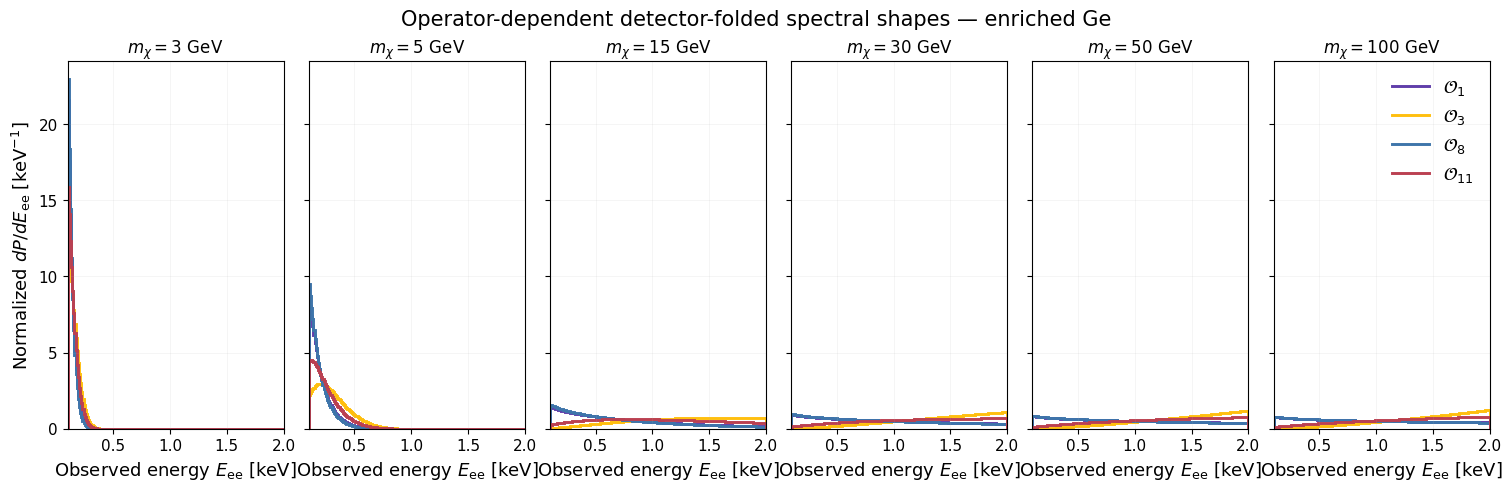

In [13]:
if PLOT_NORMALIZED:
    fig, axs = plt.subplots(1,len(plot_masses),figsize=FIGURE_SIZE,sharex=True,sharey=True,
                            constrained_layout=True)
    axs = np.atleast_1d(axs)
    for ax, mass in zip(axs,plot_masses):
        for op in (1,3,8,11):
            counts = spectra[(mass,op)]
            norm = float(counts.sum())
            if norm<=0:
                print(f'No above-threshold O{op} signal for mass={mass:g} GeV; omitted')
                continue
            pdf = counts / norm / widths
            ax.stairs(pdf,view_edges,color=O_COLORS[op],lw=2.1,
                      label=rf'$\mathcal{{O}}_{{{op}}}$')
        ax.set(title=fr'$m_\chi={mass:g}\ \mathrm{{GeV}}$',
               xlim=(view_edges[0],view_edges[-1]),ylim=(0,None))
        ax.tick_params(labelsize=11)
        ax.set_xlabel(r'Observed energy $E_{\rm ee}$ [keV]',fontsize=FONT_SIZE)
        ax.grid(alpha=.15,lw=.6)
    axs[0].set_ylabel(r'Normalized $dP/dE_{\rm ee}$ [keV$^{-1}$]',fontsize=FONT_SIZE)
    handles,labels = axs[-1].get_legend_handles_labels()
    if handles: axs[-1].legend(loc='upper right',frameon=False,fontsize=FONT_SIZE)
    fig.suptitle(r'Operator-dependent detector-folded spectral shapes — enriched Ge',fontsize=FONT_SIZE+2)
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True,exist_ok=True)
        for ext in ('pdf','png'):
            p=FIGURE_DIR/f'nreft_normalized_O8_O11.{ext}'
            fig.savefig(p,dpi=FIGURE_DPI,bbox_inches='tight')
        print('Saved:',FIGURE_DIR/'nreft_normalized_O8_O11.pdf')
    plt.show()
else:
    print('PLOT_NORMALIZED=False: skipped normalized spectra.')

## 7 · Absolute rates (optional)

The amplitudes correspond to the **same chosen numerical coefficient** $|c_p|=|c_{\rm ref}|$ for each operator, not to equal WIMP–nucleon cross sections. This plot complements the normalized shape comparison.

Saved: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\nreft_test\figures\nreft_absolute_O8_O11.pdf


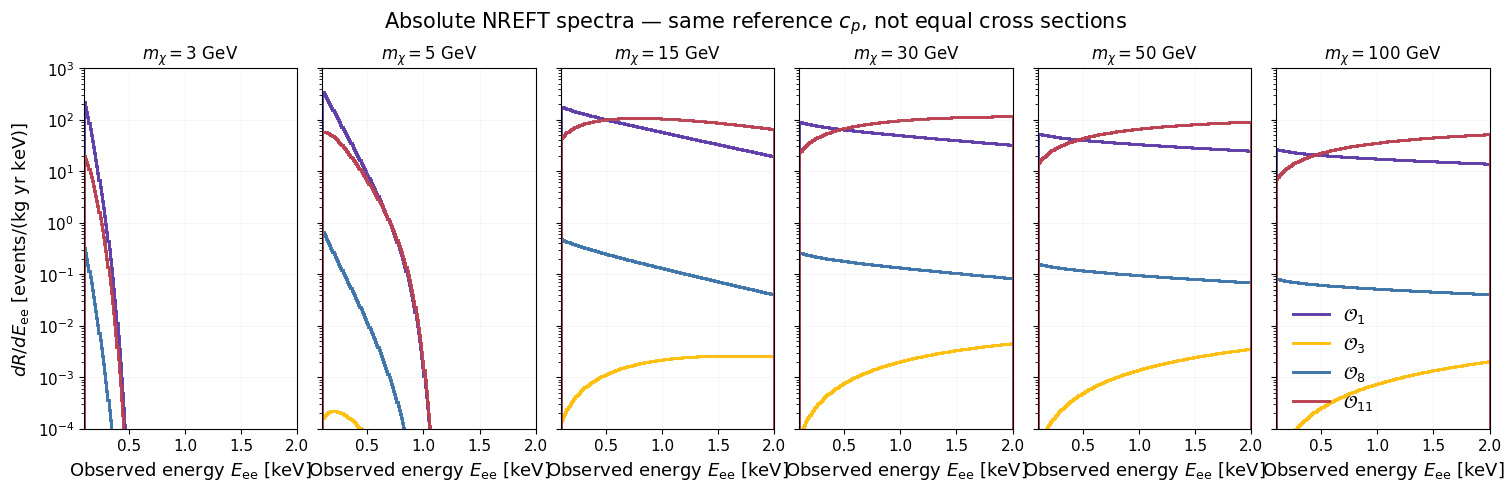

In [14]:
if PLOT_ABSOLUTE:
    days_per_year = cfg['analysis']['days_per_year']
    fig, axs = plt.subplots(1,len(plot_masses),figsize=FIGURE_SIZE,sharex=True,sharey=True,
                            constrained_layout=True)
    axs = np.atleast_1d(axs)
    for ax,mass in zip(axs,plot_masses):
        for op in (1,3,8,11):
            rate = spectra[(mass,op)]/widths*days_per_year
            positive = np.where(rate>0,rate,np.nan) if ABSOLUTE_LOG_Y else rate
            ax.stairs(positive,view_edges,color=O_COLORS[op],lw=2.1,
                      label=rf'$\mathcal{{O}}_{{{op}}}$')
        ax.set(title=fr'$m_\chi={mass:g}\ \mathrm{{GeV}}$',
               xlim=(view_edges[0],view_edges[-1]))
        if ABSOLUTE_LOG_Y:
            ax.set_yscale('log')
        else:
            ax.set_ylim(bottom=0)
        ax.set_xlabel(r'Observed energy $E_{\rm ee}$ [keV]',fontsize=FONT_SIZE)
        ax.tick_params(labelsize=11)
        ax.grid(alpha=.15,lw=.6)
    axs[0].set_ylabel(r'$dR/dE_{\rm ee}$ [events/(kg yr keV)]',fontsize=FONT_SIZE)
    axs[0].set_ylim(1e-4, 1e3)
    handles,labels = axs[-1].get_legend_handles_labels()
    if handles: axs[-1].legend(loc='best',frameon=False,fontsize=FONT_SIZE)
    fig.suptitle(r'Absolute NREFT spectra — same reference $c_p$, not equal cross sections',
                 fontsize=FONT_SIZE+2)
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True,exist_ok=True)
        for ext in ('pdf','png'):
            p=FIGURE_DIR/f'nreft_absolute_O8_O11.{ext}'
            fig.savefig(p,dpi=FIGURE_DPI,bbox_inches='tight')
        print('Saved:',FIGURE_DIR/'nreft_absolute_O8_O11.pdf')
    plt.show()
else:
    print('PLOT_ABSOLUTE=False: skipped absolute spectra.')

## 8 · Run summary

The *run* is kept separate from the five SI poster figures. Enable the configuration/run flags only when updating the numerical calculation. Plots always display the saved run's actual configuration, not hypothetical edits from this notebook.

In [15]:
if run is not None:
    print('Run ID:',run['manifest']['run_id'])
    print('Source revision:',run['manifest']['source'].get('git_commit','unavailable'))
    print('Cache hits/misses:',run['manifest']['cache']['hits'],run['manifest']['cache']['misses'])
    print('Convergence checks:',len(run['convergence']),
          'passed:',all(c['passed'] for c in run['convergence']))
    if run['limits']:
        print('Saved coefficient limits:',len(run['limits']),
              '(units GeV^-2, not SI cross section)')
else:
    print('No run was opened or executed.')

Run ID: 8b589378cfec8629cf78680b2771a85b1524eddfb84ccfd9a3cfe8ad0513d28a
Source revision: 5b8bc0d737f0034c00ac67190826b755676be8f3
Cache hits/misses: 211 0
Convergence checks: 57 passed: True
Saved coefficient limits: 24 (units GeV^-2, not SI cross section)
